# code_107 · Padding repairs, checkpoints and measured CPU resources

**Book:** section 21.5. A self-contained neural-training laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_21_GUIDE.md), [run evidence](../CHAPTER_21_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_107).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2207;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2207


<a id="padding"></a>
 ## A payload target and a recording shortcut
 Independently generate train/development/final cohorts of 200/80/200 padded sequences, balanced by binary label. Valid readings have mean 1 or 1.12 and noise SD 0.2. Training/development label-zero records have eight valid readings and label-one records twenty-four; final recording lengths reverse that association. This is a deliberate collection shift, not a population forecast. Fixed neural logistic heads use either the unmasked padded mean or the valid-reading mean. Both feature standardizers use training records only. Length masks come from admitted counts, not a rule that every numerical zero is missing. No final-driven selection occurs.


,feature,train_accuracy,development_accuracy,final_accuracy,final_Brier
0,Unmasked,1.000,1.00,0.000,0.991835
1,Masked,0.815,0.95,0.885,0.093169


Tiny-set accuracy: 1.0 checkpoint exact: True


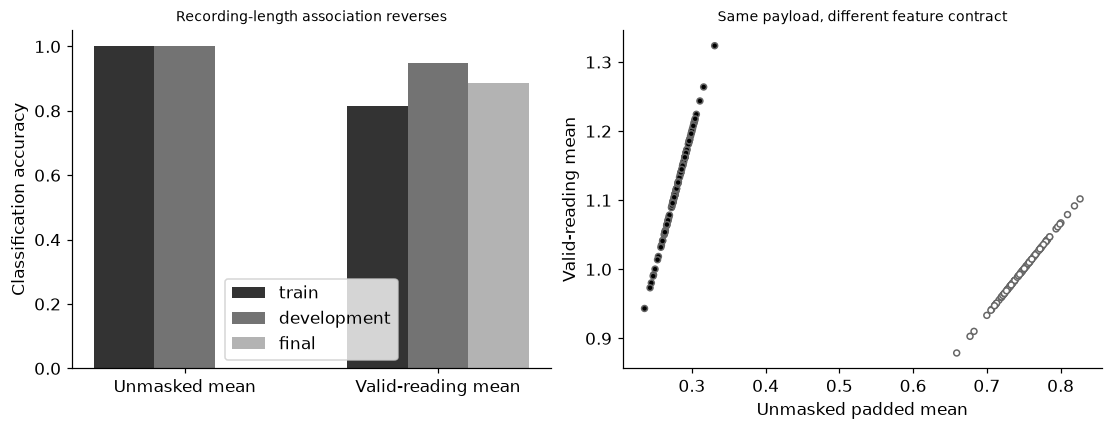

In [2]:
import copy,io
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss,accuracy_score
def cohort(n,reversed_lengths=False):
    labels=np.tile([0,1],n//2);rng.shuffle(labels);lengths=np.where(labels==0,24 if reversed_lengths else 8,8 if reversed_lengths else 24);mask=np.arange(32)[None,:]<lengths[:,None];values=1+.12*labels[:,None]+rng.normal(0,.2,(n,32));padded=np.where(mask,values,0.)
    return padded,mask,lengths,labels
train,train_mask,train_lengths,ytrain=cohort(200);dev,dev_mask,dev_lengths,ydev=cohort(80);final,final_mask,final_lengths,yfinal=cohort(200,True)
def features(values,mask):return {'Unmasked':values.mean(1)[:,None],'Masked':(np.sum(np.where(mask,values,0.),axis=1)/mask.sum(1))[:,None]}
train_features=features(train,train_mask);dev_features=features(dev,dev_mask);final_features=features(final,final_mask);rows=[];models={};scalers={}
for name,values in train_features.items():
    scaler=StandardScaler().fit(values);scalers[name]=scaler;xx=torch.tensor(scaler.transform(values));yy=torch.tensor(ytrain,dtype=torch.float64)[:,None];torch.manual_seed(SEED);model=nn.Linear(1,1);optimizer=torch.optim.Adam(model.parameters(),lr=.1)
    for step in range(600):
        optimizer.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(model(xx),yy);loss.backward();optimizer.step()
    model.eval();models[name]=model
    with torch.no_grad():
        p_train=torch.sigmoid(model(xx)).numpy().ravel();p_dev=torch.sigmoid(model(torch.tensor(scaler.transform(dev_features[name])))).numpy().ravel();p_final=torch.sigmoid(model(torch.tensor(scaler.transform(final_features[name])))).numpy().ravel()
    rows.append({'feature':name,'train_accuracy':float(accuracy_score(ytrain,p_train>=.5)),'development_accuracy':float(accuracy_score(ydev,p_dev>=.5)),'final_accuracy':float(accuracy_score(yfinal,p_final>=.5)),'final_Brier':float(brier_score_loss(yfinal,p_final))})
extended=np.pad(final,((0,0),(0,32)));extended_mask=np.pad(final_mask,((0,0),(0,32)),constant_values=False);extended_features=features(extended,extended_mask)
np.testing.assert_allclose(final_features['Masked'],extended_features['Masked'],atol=1e-12)
assert not np.allclose(final_features['Unmasked'],extended_features['Unmasked'])
with torch.no_grad():
    original=torch.sigmoid(models['Masked'](torch.tensor(scalers['Masked'].transform(final_features['Masked']))));extended_p=torch.sigmoid(models['Masked'](torch.tensor(scalers['Masked'].transform(extended_features['Masked']))));torch.testing.assert_close(original,extended_p,atol=1e-12,rtol=1e-12)
# Tiny-set overfitting is a plumbing check, not generalization evidence.
tiny_x=torch.tensor(rng.normal(size=(8,2)));tiny_y=torch.tensor([0.,1.,0.,1.,1.,0.,1.,0.])[:,None];torch.manual_seed(SEED+1);tiny=nn.Sequential(nn.Linear(2,32),nn.Tanh(),nn.Linear(32,1));optimizer=torch.optim.Adam(tiny.parameters(),lr=.05)
def update(model,opt):
    opt.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(model(tiny_x),tiny_y);loss.backward();opt.step();return float(loss.detach())
for step in range(1000):tiny_loss=update(tiny,optimizer)
with torch.no_grad():tiny_accuracy=float(((tiny(tiny_x)>0)==tiny_y.bool()).double().mean())
assert tiny_accuracy==1.
mismatch_caught=False
try:torch.utils.data.TensorDataset(tiny_x,tiny_y[:-1])
except AssertionError:mismatch_caught=True
assert mismatch_caught and tiny_x.device.type=='cpu' and tiny_x.dtype==torch.float64
# Unequal micro-batches must be weighted by record count, not averaged equally.
full=nn.Linear(2,1);micro=copy.deepcopy(full);full.zero_grad();nn.functional.binary_cross_entropy_with_logits(full(tiny_x),tiny_y).backward();micro.zero_grad()
for start,end in [(0,3),(3,6),(6,8)]:
    (nn.functional.binary_cross_entropy_with_logits(micro(tiny_x[start:end]),tiny_y[start:end])*(end-start)/8).backward()
gradient_error=max(float(torch.max(torch.abs(a.grad-b.grad))) for a,b in zip(full.parameters(),micro.parameters()));assert gradient_error<1e-12
clipped=nn.Linear(2,1);clipped.zero_grad();(1e6*torch.mean((clipped(tiny_x)-tiny_y)**2)).backward();before_clip=float(nn.utils.clip_grad_norm_(clipped.parameters(),1.));after_clip=float(torch.sqrt(sum(torch.sum(p.grad**2) for p in clipped.parameters())));assert before_clip>1 and after_clip<=1+1e-12
# Save state in memory, reload into a new model/optimizer, and compare the next update.
buffer=io.BytesIO();torch.save({'model':tiny.state_dict(),'optimizer':optimizer.state_dict(),'rng':torch.get_rng_state()},buffer);update(tiny,optimizer);expected=[p.detach().clone() for p in tiny.parameters()]
buffer.seek(0);checkpoint=torch.load(buffer,map_location='cpu',weights_only=True);restored=nn.Sequential(nn.Linear(2,32),nn.Tanh(),nn.Linear(32,1));restored.load_state_dict(checkpoint['model']);restored_optimizer=torch.optim.Adam(restored.parameters(),lr=.05);restored_optimizer.load_state_dict(checkpoint['optimizer']);torch.set_rng_state(checkpoint['rng']);update(restored,restored_optimizer)
for a,b in zip(expected,restored.parameters()):torch.testing.assert_close(a,b,atol=0,rtol=0)
sums={str(dtype):float(torch.tensor([1e8,1.,-1e8],dtype=dtype).sum()) for dtype in [torch.float32,torch.float64]}
RESULTS.update(padding_metrics=rows,masked_padding_probability_max_difference=float(torch.max(torch.abs(original-extended_p))),tiny_set_accuracy=tiny_accuracy,tiny_set_final_loss=tiny_loss,data_loader_mismatch_caught=mismatch_caught,microbatch_gradient_max_error=gradient_error,gradient_norm_before_clip=before_clip,gradient_norm_after_clip=after_clip,checkpoint_next_step_exact=True,precision_sums=sums,resource_batch_shapes=[[b,128,16] for b in [8,32,128]],resource_input_tensor_bytes=[b*128*16*4 for b in [8,32,128]])
display(pd.DataFrame(rows));print('Tiny-set accuracy:',tiny_accuracy,'checkpoint exact:',True)
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(2)
for index,key in enumerate(['train_accuracy','development_accuracy','final_accuracy']):axes[0].bar(xx+(index-1)*.24,[r[key] for r in rows],.24,color=str(.2+index*.25),label=key.split('_')[0])
axes[0].set(xticks=xx,xticklabels=['Unmasked mean','Valid-reading mean'],ylim=(0,1.05),ylabel='Classification accuracy',title='Recording-length association reverses');axes[0].legend()
axes[1].scatter(final_features['Unmasked'].ravel(),final_features['Masked'].ravel(),c=yfinal,cmap='Greys',edgecolors='.4',s=15);axes[1].set(xlabel='Unmasked padded mean',ylabel='Valid-reading mean',title='Same payload, different feature contract');plt.show()


<a id="resources"></a>
 ## Measure native CPU process resources honestly
 Run nine fresh child processes with this same interpreter: batch sizes 8/32/128, three repeats each. The child code, model and random inputs are all inline. Each profiles a float32 pointwise window MLP, one warmup and five timed AdamW updates. Maximum resident set size is the OS process high-water mark, including the interpreter, libraries, allocator, inputs and training; it is not tensor-only allocation or GPU memory. Darwin reports ru_maxrss in bytes and Linux in KiB. Timing/resource observations vary and are retained separately from deterministic RESULT assertions. The book renderer replays these original measured observations for its vector plot; ordinary notebook runs measure anew.


In [3]:
# RESOURCE_MEASUREMENT_CELL
import subprocess,sys
child=r"""
import torch,time,resource,platform,json,sys
from torch import nn
torch.set_num_threads(1);torch.manual_seed(9107);torch.set_default_dtype(torch.float32)
batch=int(sys.argv[1]);baseline=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
model=nn.Sequential(nn.Linear(16,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU(),nn.Linear(128,1));optimizer=torch.optim.AdamW(model.parameters(),lr=.001);x=torch.randn(batch,128,16);y=torch.randn(batch,128,1)
def step():
    optimizer.zero_grad();loss=torch.mean((model(x)-y)**2);loss.backward();optimizer.step()
step();start=time.perf_counter()
for _ in range(5):step()
elapsed=(time.perf_counter()-start)/5;peak=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
if platform.system() not in ['Darwin','Linux']:raise RuntimeError('This profile declares Darwin/Linux ru_maxrss units only')
unit=1 if platform.system()=='Darwin' else 1024
print(json.dumps({'batch':batch,'peak_RSS_bytes':int(peak*unit),'baseline_RSS_bytes':int(baseline*unit),'seconds_per_update':elapsed,'platform':platform.system(),'torch':torch.__version__,'dtype':'float32','threads':1,'timed_updates':5}))
"""
resource_profile=[]
for batch in [8,32,128]:
    for replicate in range(3):
        run=subprocess.run([sys.executable,'-c',child,str(batch)],check=True,capture_output=True,text=True,timeout=60);observation=json.loads(run.stdout);observation['replicate']=replicate;resource_profile.append(observation)
assert len(resource_profile)==9 and all(r['peak_RSS_bytes']>=r['baseline_RSS_bytes']>0 and r['seconds_per_update']>0 for r in resource_profile)
display(pd.DataFrame(resource_profile))


,batch,peak_RSS_bytes,baseline_RSS_bytes,seconds_per_update,platform,torch,dtype,threads,timed_updates,replicate
0,8,316981248,213778432,0.000604,Darwin,2.14.1,float32,1,5,0
1,8,316964864,213532672,0.000600,Darwin,2.14.1,float32,1,5,1
2,8,316751872,213385216,0.000597,Darwin,2.14.1,float32,1,5,2
3,32,325107712,213450752,0.001459,Darwin,2.14.1,float32,1,5,0
4,32,324812800,213417984,0.001447,Darwin,2.14.1,float32,1,5,1
5,32,325074944,213499904,0.001395,Darwin,2.14.1,float32,1,5,2
6,128,357761024,213499904,0.005243,Darwin,2.14.1,float32,1,5,0
7,128,357580800,213565440,0.005442,Darwin,2.14.1,float32,1,5,1
8,128,357269504,213237760,0.005438,Darwin,2.14.1,float32,1,5,2


<a id="resource-interpretation"></a>
 ## Observation, accounting and deployment are different claims
 The input-tensor byte counts in RESULTS are exact shape×float32 item-size accounting. They are not a prediction of whole-process peak RSS. Three separate process repeats show measurement variability without assuming monotone timings or memory. The tiny-set fit, caught loader mismatch, mask-invariance check, clipped gradient, weighted micro-batch check and exact next checkpoint step test distinct pieces of the training system. No one check establishes generalization, sufficient memory on another machine or safe mixed-precision execution. GPU/device-specific profiling needs a separate execution contract.


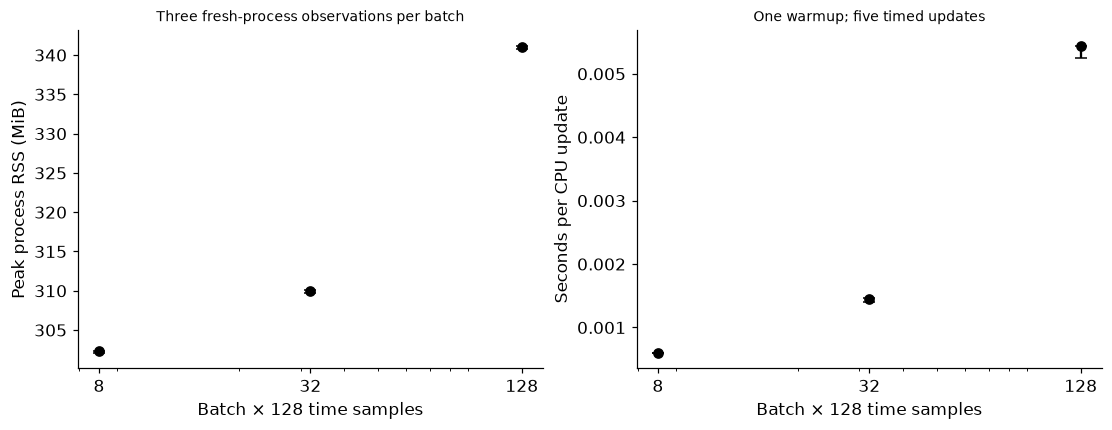

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
for ax,key,scale,label in [(axes[0],'peak_RSS_bytes',1024**2,'Peak process RSS (MiB)'),(axes[1],'seconds_per_update',1,'Seconds per CPU update')]:
    for batch in [8,32,128]:
        observed=np.array([r[key]/scale for r in resource_profile if r['batch']==batch]);median=float(np.median(observed));ax.errorbar(batch,median,yerr=np.array([[median-observed.min()],[observed.max()-median]]),fmt='o',color='black',capsize=4)
    ax.set(xscale='log',xticks=[8,32,128],xticklabels=['8','32','128'],xlabel='Batch × 128 time samples',ylabel=label)
axes[0].set_title('Three fresh-process observations per batch');axes[1].set_title('One warmup; five timed updates');plt.show()
assert all(r['dtype']=='float32' and r['threads']==1 for r in resource_profile)


In [5]:
summary={'example_id':'code_107','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['padding shortcut and explicit masking', 'tiny-set overfitting', 'weighted microbatch gradients', 'checkpoint exact next step', 'actual process peak RSS and CPU timing'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["padding shortcut and explicit masking", "tiny-set overfitting", "weighted microbatch gradients", "checkpoint exact next step", "actual process peak RSS and CPU timing"], "elapsed_seconds": 8.708, "example_id": "code_107", "hardware": "Darwin arm64 CPU", "resource_observations": [{"baseline_RSS_bytes": 213778432, "batch": 8, "dtype": "float32", "peak_RSS_bytes": 316981248, "platform": "Darwin", "replicate": 0, "seconds_per_update": 0.0006036083999788388, "threads": 1, "timed_updates": 5, "torch": "2.14.1"}, {"baseline_RSS_bytes": 213532672, "batch": 8, "dtype": "float32", "peak_RSS_bytes": 316964864, "platform": "Darwin", "replicate": 1, "seconds_per_update": 0.0005996416002744809, "threads": 1, "timed_updates": 5, "torch": "2.14.1"}, {"baseline_RSS_bytes": 213385216, "batch": 8, "dtype": "float32", "peak_RSS_bytes": 316751872, "platform": "Darwin", "replicate": 2, "seconds_per_update": 0.0005972499988274649, "threads": 1, "timed_update